In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch
import time

from rl4co.envs import CVRPEnv
from rl4co.models import REINFORCE, AttentionModelPolicy, PolyNet
from rl4co.models.zoo.decomposition import DECOMP, BaryCenterDecomp, Naive
from rl4co.utils.trainer import RL4COTrainer
from lightning.pytorch.loggers import WandbLogger

/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


In [3]:
torch.manual_seed(42)

In [10]:
device = "cpu"

env = CVRPEnv(generator_params={'num_loc': 100}).to(device)

td = env.reset(batch_size=[4]).to(device)

policy_params = {"its": 4, "temp": 0.1, "r": 0.9}
policy = AttentionModelPolicy(env_name=env.name, 
                              embed_dim=128,
                              num_encoder_layers=3,
                              num_heads=8,
                            ).to(device)
naive_pol = Naive().to(device)
decomp_pol = BaryCenterDecomp(4, policy=policy, naive_policy=naive_pol, **policy_params).to(device)

model = DECOMP(env,
               policy=decomp_pol,
               baseline="rollout",
               baseline_kwargs={"n_epochs": 1},
               batch_size=16,
               train_data_size=10_000,
               val_data_size=1_000,
               optimizer_kwargs={"lr": 1e-4},
               **policy_params
               ).to(device)

`None` was provided as encoder. Using `NoEncoder`.
/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'env' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['env'])`.
/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'policy' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['policy'])`.


In [ ]:
td = env.reset(batch_size=[4]).to(device)

Tour lengths: ['54.39', '51.54', '67.77', '83.74']


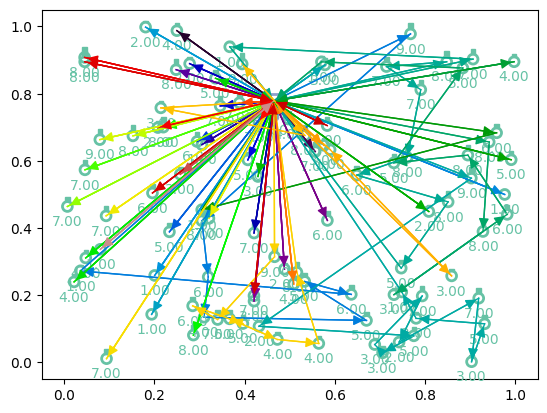

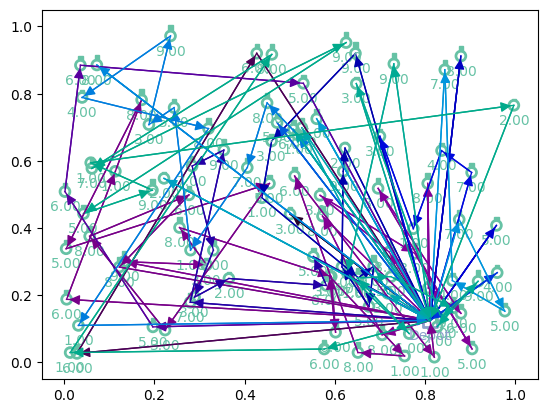

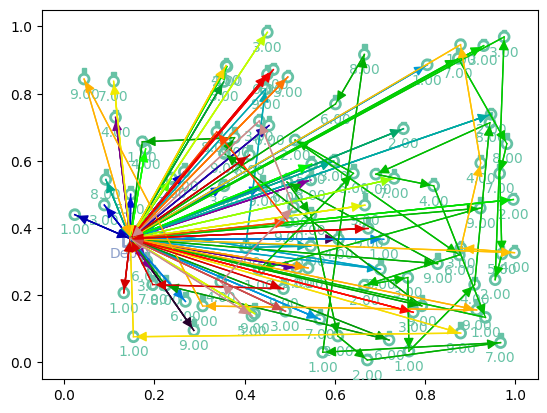

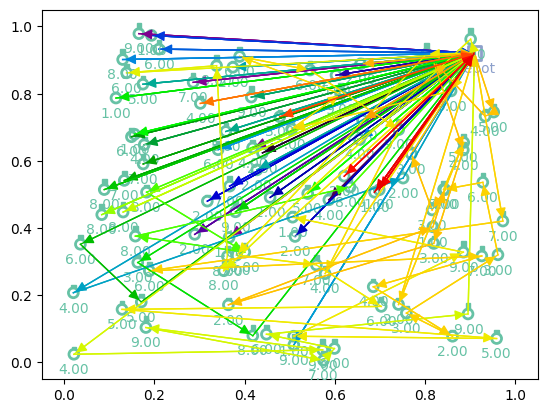

In [11]:
policy = model.policy.to(device)
out = policy(td.clone(), env, phase="test", decode_type="greedy", return_actions=True)

# Plotting
print(f"Tour lengths: {[f'{-r.item():.2f}' for r in out['reward']]}")
for td, actions in zip(td, out['actions'].cpu()):
    env.render(td, actions)

In [12]:
trainer = RL4COTrainer(
    max_epochs=2,
    accelerator="cpu",
    devices=1,
)

/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/accelerator_connector.py:556: You passed `Trainer(accelerator='cpu', precision='16-mixed')` but AMP with fp16 is not supported on CPU. Using `precision='bf16-mixed'` instead.
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/logger_connector/logger_connector.py:75: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable

In [13]:
trainer.fit(model)

Overriding gradient_clip_val to None for 'automatic_optimization=False' models
/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:44: attribute 'policy' removed from hparams because it cannot be pickled
val_file not set. Generating dataset instead
test_file not set. Generating dataset instead

  | Name     | Type             | Params
----------------------------------------------
0 | env      | CVRPEnv          | 0     
1 | policy   | BaryCenterDecomp | 694 K 
2 | baseline | WarmupBaseline   | 694 K 
----------------------------------------------
1.4 M     Trainable params
0         Non-trainable params
1.4 M     Total params
5.553     Total estimated model params size (MB)


Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:441: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:441: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Epoch 0:  29%|██▉       | 183/625 [1:23:16<3:21:07,  0.04it/s, v_num=5, train/reward=-30.7, train/loss=-49.1]

/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/trainer/call.py:54: Detected KeyboardInterrupt, attempting graceful shutdown...


Tour lengths: ['19.19', '23.79', '20.90', '20.07']


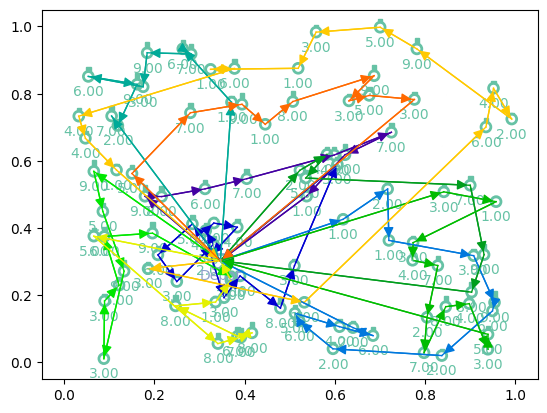

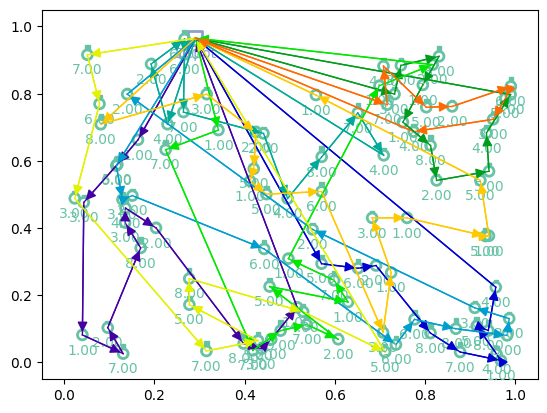

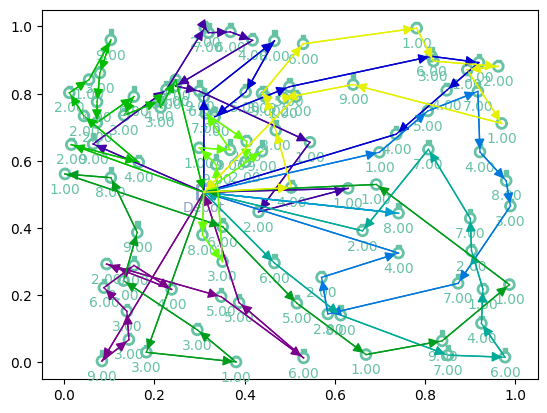

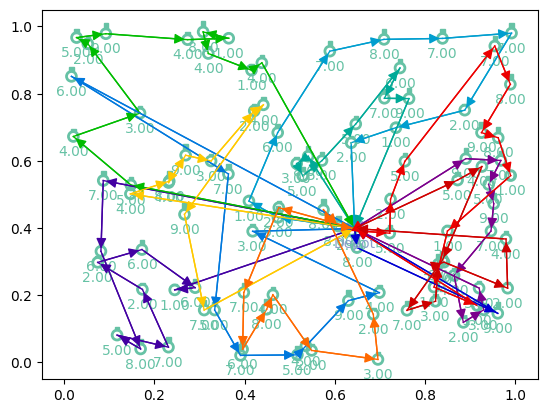

In [18]:
# Greedy rollouts over trained model (same states as previous plot)
policy = model.policy.to(device)
out = policy(td.clone(), env, phase="test", decode_type="greedy", return_actions=True)

# Plotting
print(f"Tour lengths: {[f'{-r.item():.2f}' for r in out['reward']]}")
for td, actions in zip(td, out['actions'].cpu()):
    env.render(td, actions)

In [34]:
out = list(policy(td.copy(), env, phase="test", decode_type="greedy", return_actions=True))

for td, actions in zip(out[-1]["dec_td"], out[-1]["nsol"]["actions"].cpu()):
    env.render(td, actions)

In [102]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colormaps
from sklearn.cluster import KMeans

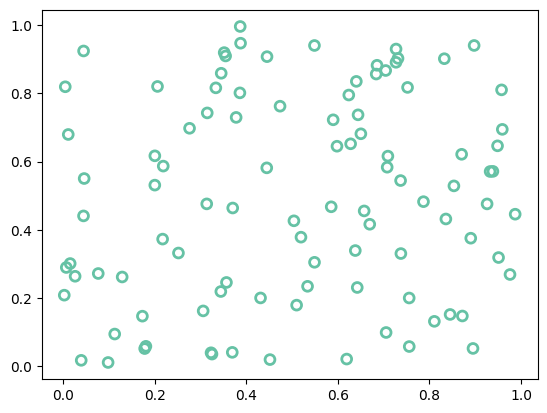

In [112]:
_, ax = plt.subplots()

locs = td["locs"][0][1:]
x, y = locs[:, 0], locs[:, 1]

# plot visited nodes
ax.scatter(
    x[1:],
    y[1:],
    edgecolors=cm.Set2(0),
    facecolors="none",
    s=50,
    linewidths=2,
    marker="o",
    alpha=1,
)

In [257]:
td = env.reset(batch_size=[4]).to(device)
td_base = td.copy()
sol = policy.naive_policy(td, env, return_actions=True)

In [264]:
from tensordict.tensordict import TensorDict

In [263]:
td, actions = policy.decompose(td, env, sol)

res = TensorDict({
    "actions": actions,
    "reward": torch.zeros((td.batch_size[0]), dtype=torch.float32)},
    batch_size=td.batch_size[0],
    device=td.device
)

nsol = policy.recompose(td, actions)


IndexError: too many indices for tensor of dimension 2

(-0.05, 1.05)

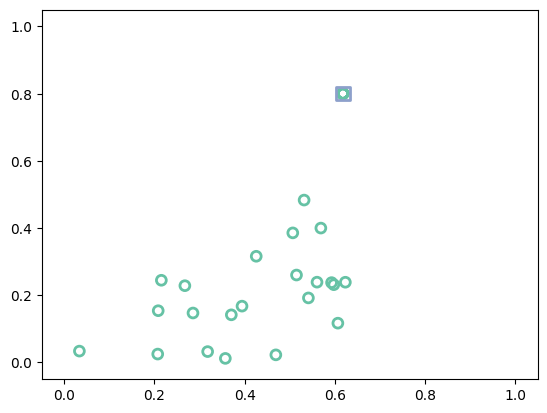

In [231]:
_, ax = plt.subplots()

locs = td["locs"][6]
x, y = locs[:, 0], locs[:, 1]

# plot visited nodes
ax.scatter(
    x[1:],
    y[1:],
    edgecolors=cm.Set2(0),
    facecolors="none",
    s=50,
    linewidths=2,
    marker="o",
    alpha=1,
)

# plot depot
ax.scatter(
    td_base["locs"][1][0, 0],
    td_base["locs"][1][0, 1],
    edgecolors=cm.Set2(2),
    facecolors="none",
    s=100,
    linewidths=2,
    marker="s",
    alpha=1,
)

ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)

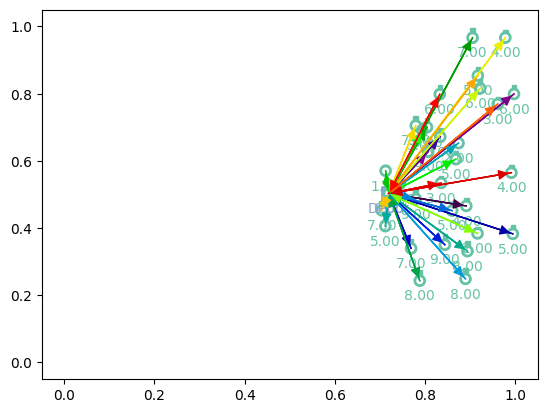

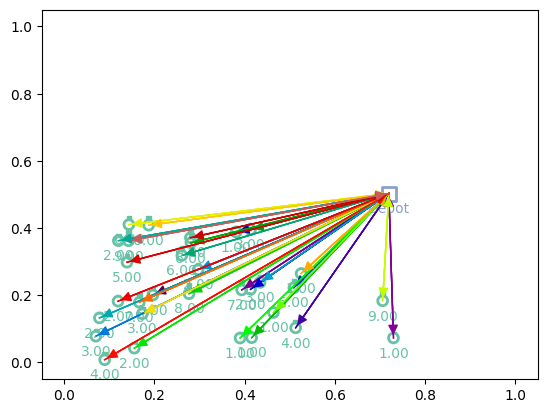

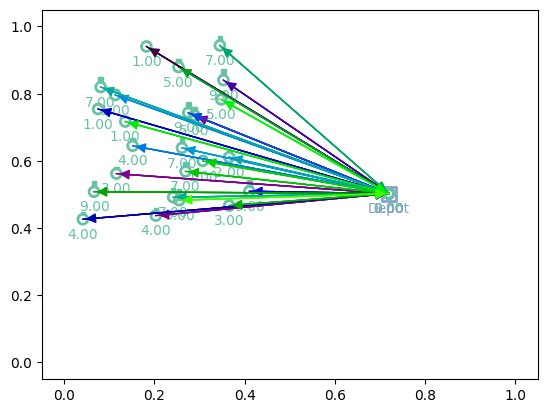

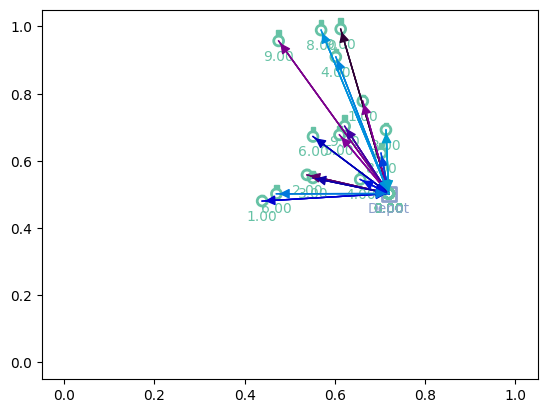

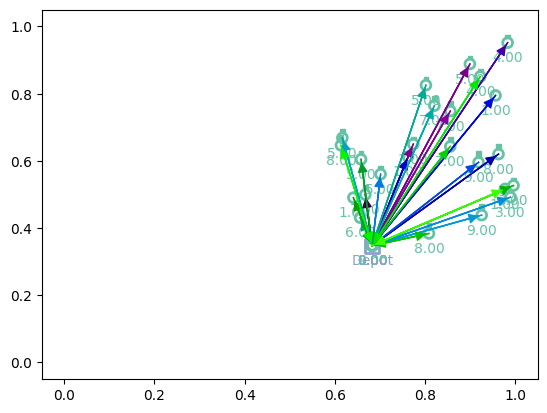

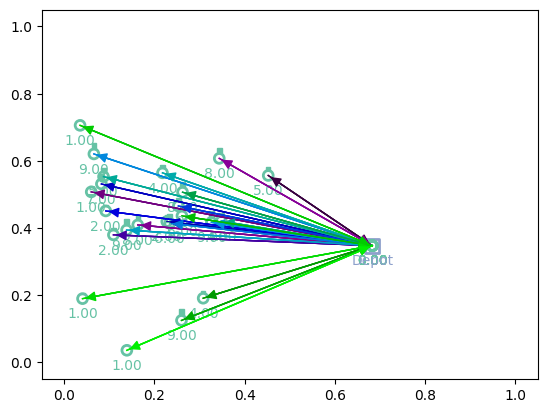

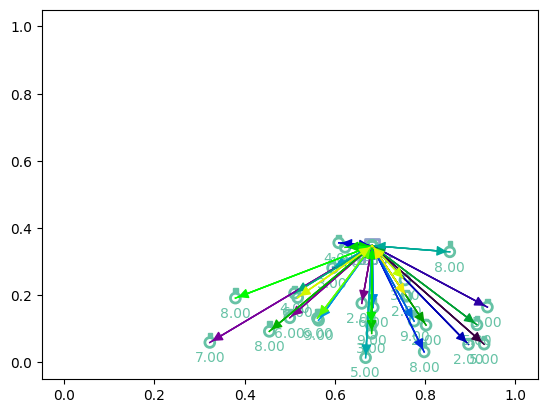

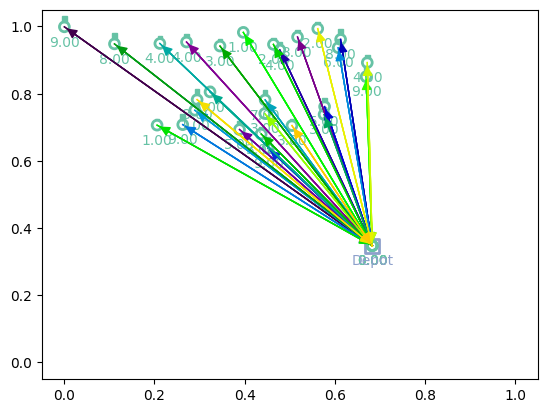

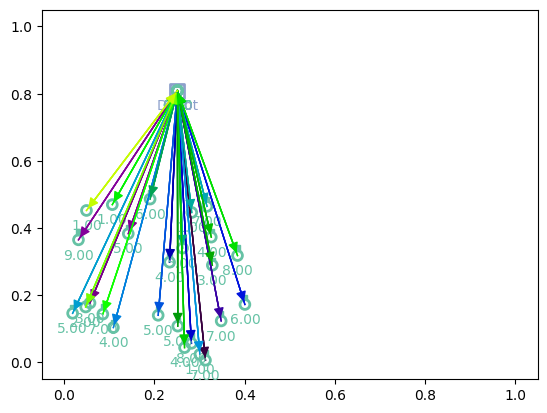

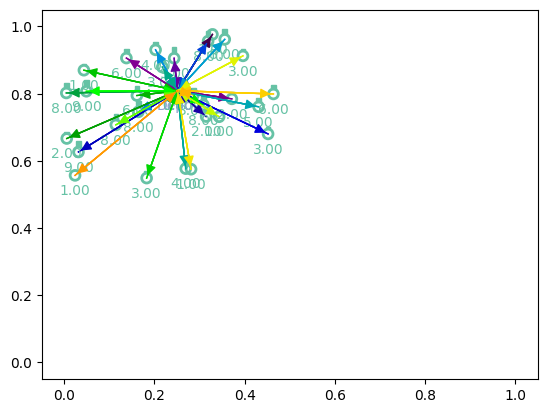

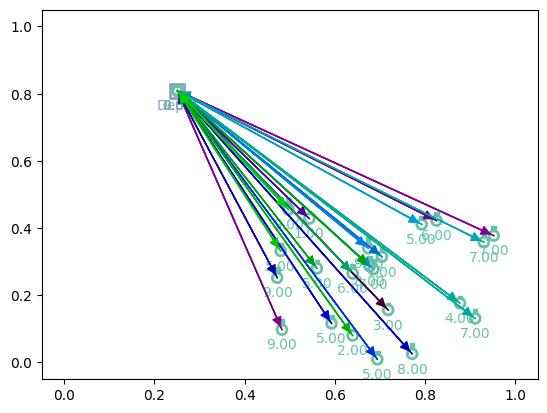

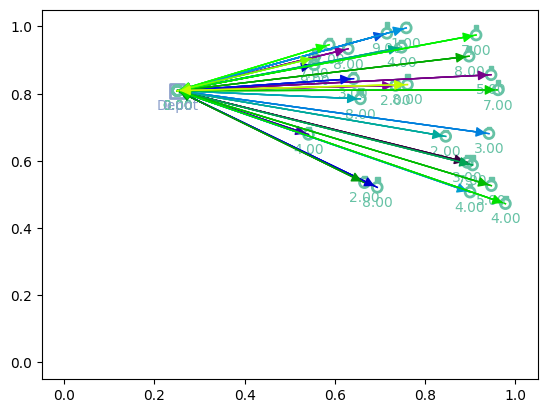

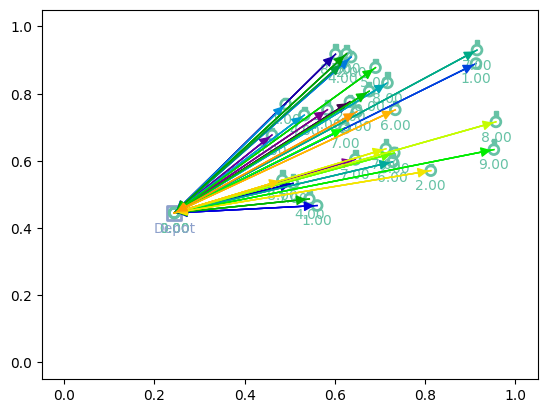

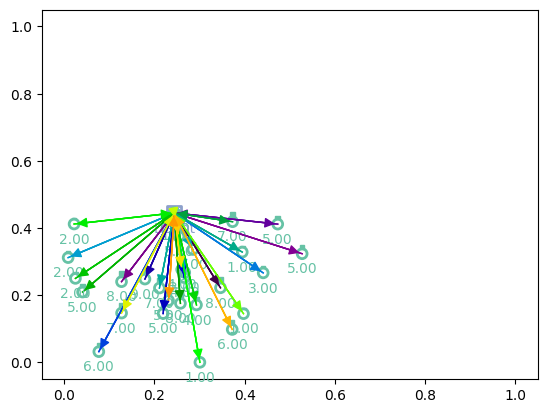

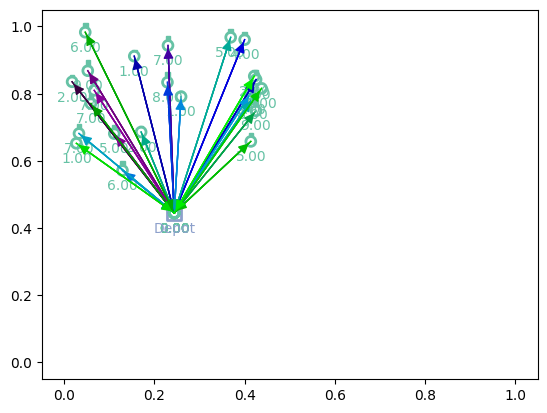

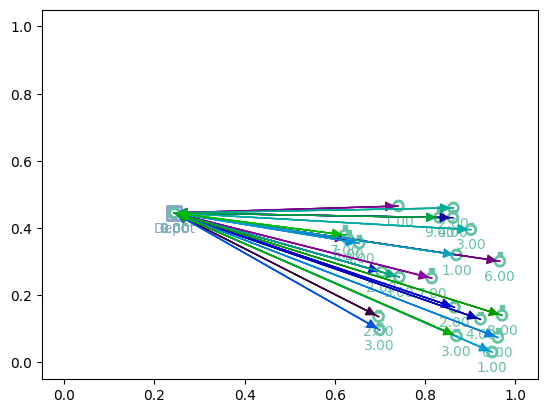

In [256]:
td = env.reset(td)
for td_, sol_ in zip(td, sol):
    env.render(td_, sol_)

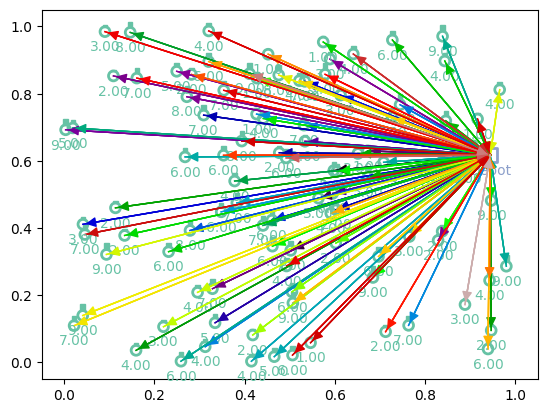

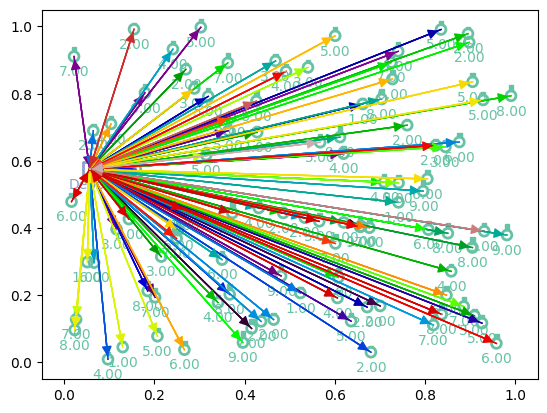

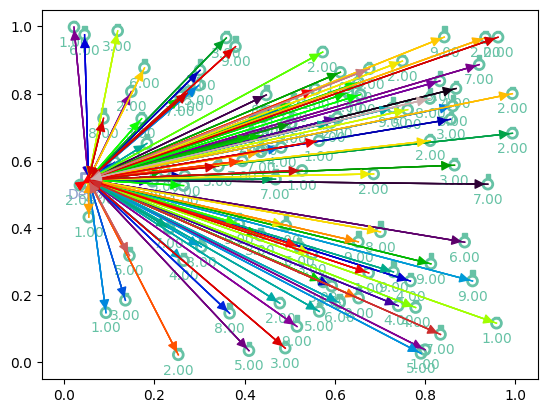

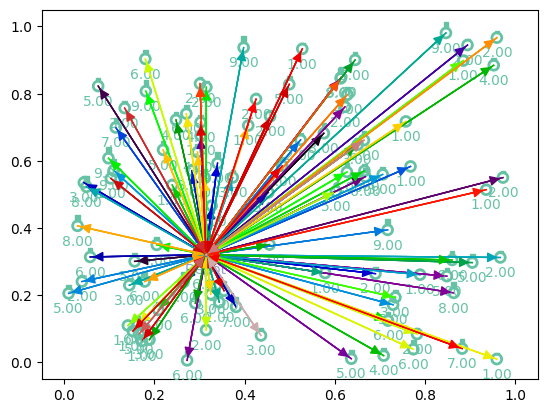

In [262]:
for td_, actions_ in zip(td, sol["actions"]):
    env.render(td_, actions_)